# Phase 2: Exploratory Data Analysis (EDA)
## Heart Disease Risk Prediction (UCI Cleveland Dataset)
**Project**: Heart Disease Risk Prediction Using Kafka, Hadoop HDFS, and Machine Learning  
**Dataset**: Processed Cleveland Dataset (UCI Machine Learning Repository ID: 45)  
**Sample Size**: 303 patient records, 13 clinical features, 1 binary diagnosis target


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

DATA_PATH = os.path.join('..', 'data', 'processed', 'heart_disease.csv')
print(f"Reading dataset from: {os.path.abspath(DATA_PATH)}")


Reading dataset from: C:\Users\pulki\OneDrive\Desktop\heart-disease-big-data\data\processed\heart_disease.csv


### 1. Dataset Shape and Column Names
Inspecting the loaded clinical records from `data/processed/heart_disease.csv`.


In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Column Names: {list(df.columns)}")
df.head(5)


Dataset Shape: 303 rows, 14 columns
Column Names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### 2. Data Types and Non-Null Counts
Inspecting data structures and storage representations.


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


### 3. Missing-Value Audit
Quantifying missing values across each clinical attribute.


In [4]:
missing = df.isna().sum()
missing_pct = (missing / len(df)) * 100
missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage (%)': missing_pct.round(2)
})
print("Missing values per column:")
print(missing_summary[missing_summary['Missing Count'] > 0])


Missing values per column:
      Missing Count  Missing Percentage (%)
ca                4                    1.32
thal              2                    0.66


*Observation: Only two features have missing entries: `ca` (4 instances, 1.32%) and `thal` (2 instances, 0.66%). These missing values represent less than 2% of total rows and are preserved for downstream pipeline handling without premature imputation.*


### 4. Target Variable Analysis (Class Distribution)
The target variable encodes coronary artery disease status:
- **0**: Absence (< 50% diameter narrowing in all major coronary vessels)
- **1**: Presence (> 50% diameter narrowing in at least 1 major vessel)


Class 0 (Absence):  164 (54.13%)
Class 1 (Presence): 139 (45.87%)


C:\Users\pulki\AppData\Local\Temp\ipykernel_11988\1690797857.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_counts.index, y=target_counts.values, palette=colors, ax=axes[0])


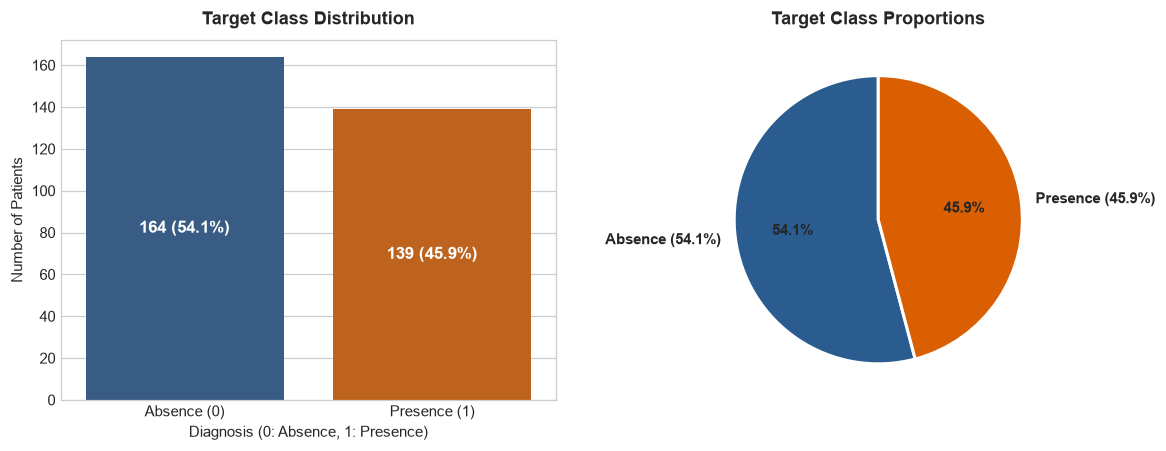

In [5]:
target_counts = df['target'].value_counts().sort_index()
target_pct = df['target'].value_counts(normalize=True).sort_index() * 100

print(f"Class 0 (Absence):  {target_counts[0]} ({target_pct[0]:.2f}%)")
print(f"Class 1 (Presence): {target_counts[1]} ({target_pct[1]:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colors = ['#2b5c8f', '#d95f02']

# Bar chart
sns.barplot(x=target_counts.index, y=target_counts.values, palette=colors, ax=axes[0])
axes[0].set_title('Target Class Distribution', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Diagnosis (0: Absence, 1: Presence)', fontsize=10)
axes[0].set_ylabel('Number of Patients', fontsize=10)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Absence (0)', 'Presence (1)'])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Pie chart
axes[1].pie(target_counts, labels=['Absence (54.1%)', 'Presence (45.9%)'],
            colors=colors, autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 10, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Target Class Proportions', fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()


### 5. Summary Statistics for Continuous Clinical Measurements
Examining distributional statistics (mean, standard deviation, interquartile range) for continuous features.


In [6]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
desc = df[continuous_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc.round(2)


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


### 6. Age Distribution Stratified by Disease Status
Visualizing patient age profiles and their association with heart disease.


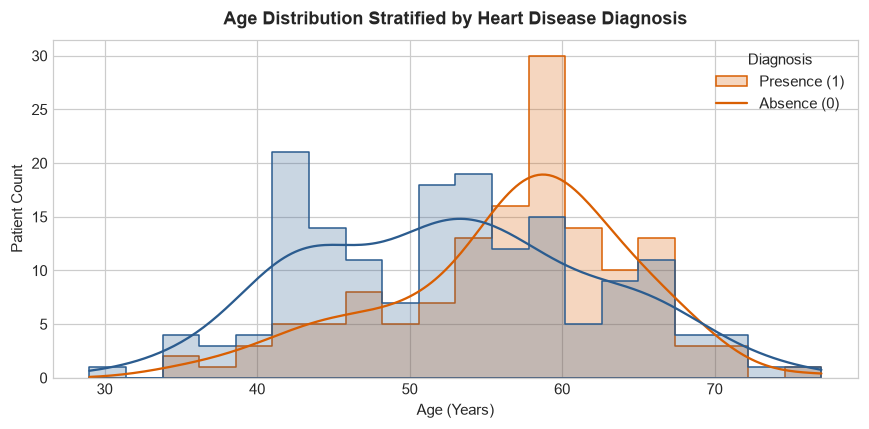

Mean age (Absence):  52.59 years
Mean age (Presence): 56.63 years


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x='age', hue='target', kde=True, bins=20,
             palette=['#2b5c8f', '#d95f02'], element='step', ax=ax)
ax.set_title('Age Distribution Stratified by Heart Disease Diagnosis', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Age (Years)', fontsize=10)
ax.set_ylabel('Patient Count', fontsize=10)
ax.legend(labels=['Presence (1)', 'Absence (0)'], title='Diagnosis')
plt.tight_layout()
plt.show()

mean_age_0 = df[df['target'] == 0]['age'].mean()
mean_age_1 = df[df['target'] == 1]['age'].mean()
print(f"Mean age (Absence):  {mean_age_0:.2f} years")
print(f"Mean age (Presence): {mean_age_1:.2f} years")


### 7. Clinical Symptom Relationships: Chest Pain (`cp`) and Exercise Angina (`exang`)
- `cp` categories: 1 = Typical Angina, 2 = Atypical Angina, 3 = Non-anginal, 4 = Asymptomatic
- `exang`: 0 = No exercise angina, 1 = Exercise-induced angina


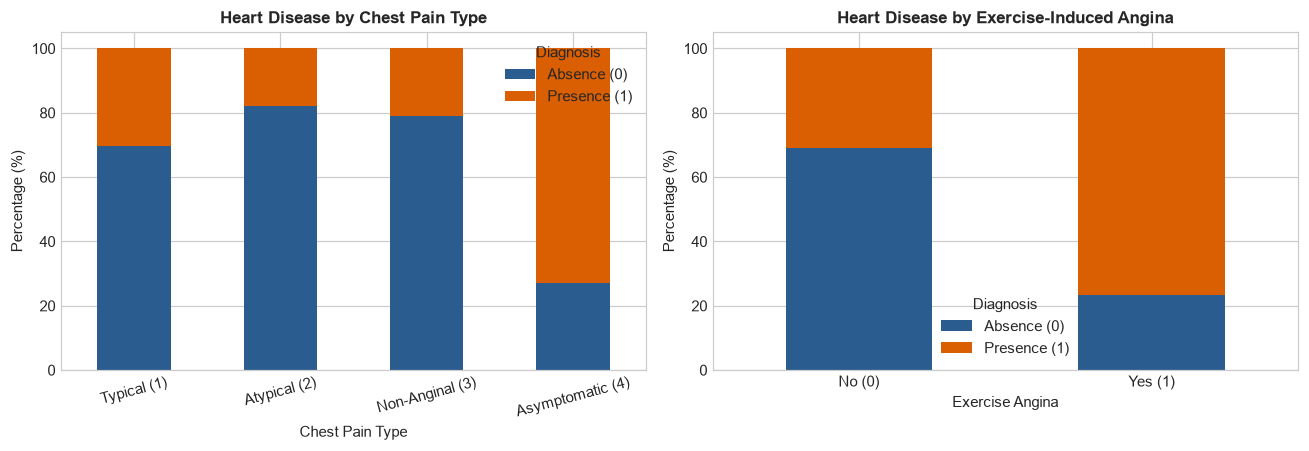

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Chest pain vs Target
cp_cross = pd.crosstab(df['cp'], df['target'], normalize='index') * 100
cp_cross.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title('Heart Disease by Chest Pain Type', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Chest Pain Type', fontsize=10)
axes[0].set_ylabel('Percentage (%)', fontsize=10)
axes[0].set_xticklabels(['Typical (1)', 'Atypical (2)', 'Non-Anginal (3)', 'Asymptomatic (4)'], rotation=15)
axes[0].legend(['Absence (0)', 'Presence (1)'], title='Diagnosis')

# Exercise angina vs Target
exang_cross = pd.crosstab(df['exang'], df['target'], normalize='index') * 100
exang_cross.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('Heart Disease by Exercise-Induced Angina', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Exercise Angina', fontsize=10)
axes[1].set_ylabel('Percentage (%)', fontsize=10)
axes[1].set_xticklabels(['No (0)', 'Yes (1)'], rotation=0)
axes[1].legend(['Absence (0)', 'Presence (1)'], title='Diagnosis')

plt.tight_layout()
plt.show()


### 8. Hemodynamic & ECG Stress Response: `thalach` and `oldpeak`
- `thalach`: Maximum heart rate achieved during exercise stress test
- `oldpeak`: ST depression induced by exercise relative to rest


C:\Users\pulki\AppData\Local\Temp\ipykernel_11988\4236564877.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='thalach', palette=['#2b5c8f', '#d95f02'], ax=axes[0])
C:\Users\pulki\AppData\Local\Temp\ipykernel_11988\4236564877.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Absence (0)', 'Presence (1)'])
C:\Users\pulki\AppData\Local\Temp\ipykernel_11988\4236564877.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='oldpeak', palette=['#2b5c8f', '#d95f02'], ax=axes[1])
C:\Users\pulki\AppData\Loc

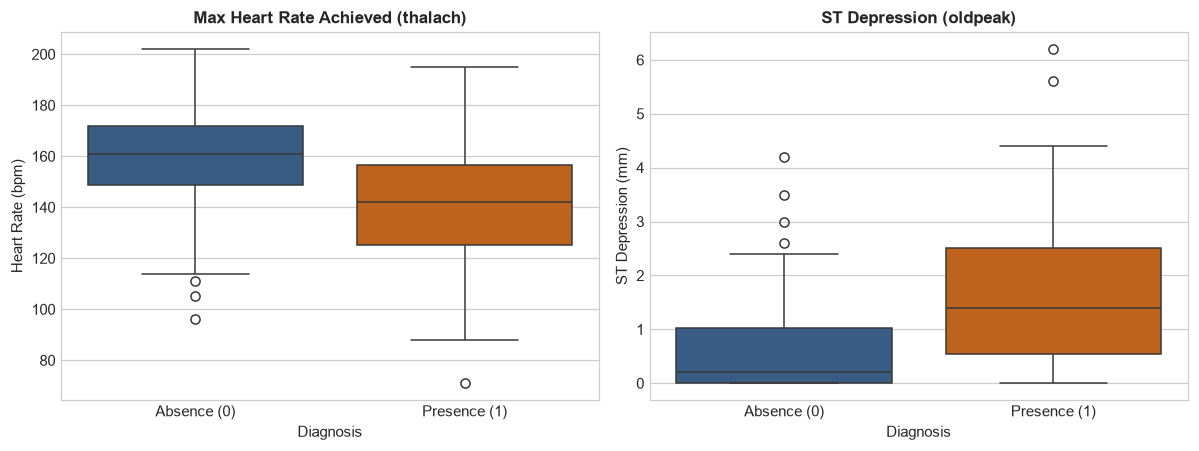

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

sns.boxplot(data=df, x='target', y='thalach', palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title('Max Heart Rate Achieved (thalach)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Diagnosis', fontsize=10)
axes[0].set_ylabel('Heart Rate (bpm)', fontsize=10)
axes[0].set_xticklabels(['Absence (0)', 'Presence (1)'])

sns.boxplot(data=df, x='target', y='oldpeak', palette=['#2b5c8f', '#d95f02'], ax=axes[1])
axes[1].set_title('ST Depression (oldpeak)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Diagnosis', fontsize=10)
axes[1].set_ylabel('ST Depression (mm)', fontsize=10)
axes[1].set_xticklabels(['Absence (0)', 'Presence (1)'])

plt.tight_layout()
plt.show()


### 9. Feature Correlation Matrix
Evaluating pairwise linear correlations among numeric clinical attributes and the diagnosis target.


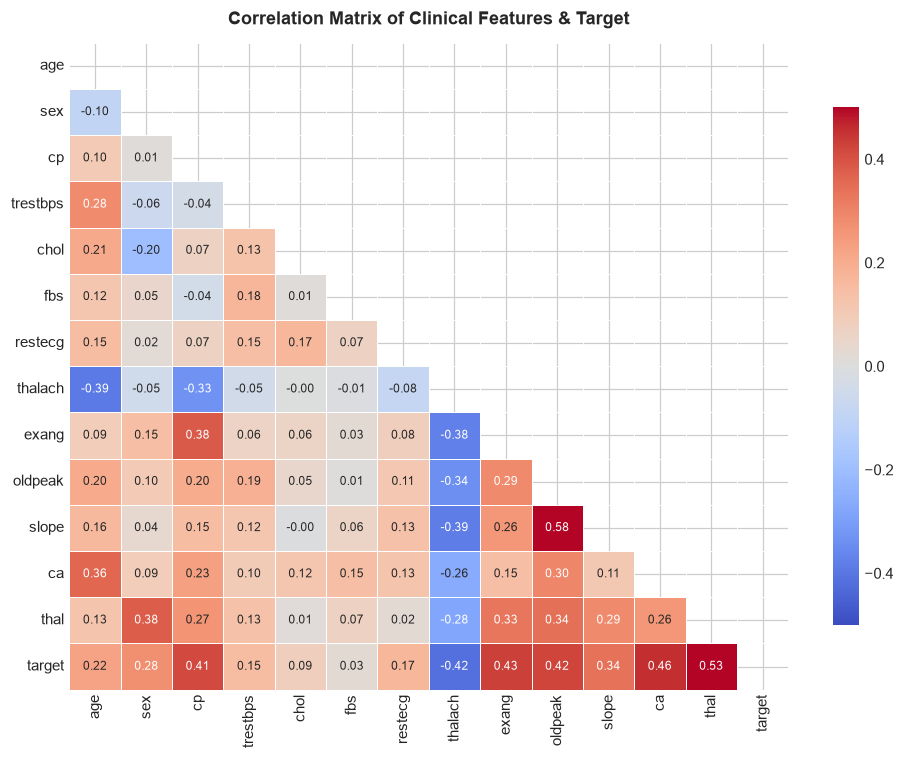

In [10]:
plt.figure(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-0.5, vmax=0.5, linewidths=0.5, cbar_kws={'shrink': 0.8}, annot_kws={'size': 8})
plt.title('Correlation Matrix of Clinical Features & Target', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### 10. Summary of Findings & Non-Causal Clinical Observations

1. **Cohort & Class Balance**:
   - The dataset consists of 303 patient records, with 164 patients (54.13%) classified as disease absence and 139 patients (45.87%) as disease presence.
   - The balanced distribution provides a solid foundation for binary classification modeling without requiring synthetic resampling.

2. **Data Completeness**:
   - Only 6 values are missing in total across the entire 303x14 matrix (`ca`: 4 missing, `thal`: 2 missing). All other 12 features have 100% completeness.

3. **Observed Clinical Correlations**:
   - **Chest Pain (`cp`)**: In this clinical referral sample, patients presenting with Type 4 (asymptomatic chest pain) had a notably higher proportion of angiographically confirmed CAD (~72%), while patients with typical and atypical angina had lower positive rates. This reflects selection bias inherent in clinical diagnostic cath referrals.
   - **Maximum Heart Rate (`thalach`)**: Shows a moderate negative correlation with disease presence ($r \approx -0.42$). Patients with heart disease reached a lower median peak heart rate (142 bpm vs 161 bpm).
   - **ST Depression (`oldpeak`)**: Elevated exercise-induced ST segment depression ($r \approx 0.42$) and exercise angina (`exang`, $r \approx 0.43$) strongly correlate with disease presence.
   - **Fluoroscopy Vessels (`ca`)**: The number of major vessels visible under fluoroscopy shows positive correlation with disease ($r \approx 0.46$).

4. **Methodological Note on Causation**:
   - These observed patterns represent statistical associations within an observational hospital screening cohort and do not establish direct individual causation. Multiple risk factors interact non-linearly, which motivates the multi-feature machine learning approach planned for subsequent phases.
